# SI3003 · Evaluación 2 · Parte II (aplicada) — Notebook base

**Profesor:** Jorge Iván Padilla Buriticá · Universidad EAFIT

Este notebook es **una ayuda, no una solución**. Trae la infraestructura (configuración, carga de datos, utilidades) y deja **esqueletos vacíos** para lo que se califica. Puede borrar, mover o cambiar lo que quiera.

| Etiqueta en la celda | Significado |
|---|---|
| `# [PROVISTO]` | Ya funciona. Léala y entiéndala; puede modificarla. |
| `# [SU TURNO]` | Aquí va **su** código o **su** análisis. |

> ⏱ **Tiempo máximo: 60 minutos.** Si una tarea se complica, avance y deje escrito qué intentó.
> 📨 **Entrega:** un único notebook **ejecutado de arriba hacia abajo**, enviado a **jipadillab@eafit.edu.co** con el asunto `[SI3003-Nombre_Apellido_Grupo_Eval02_practica]`, **hasta las 11:00 a. m.** (la celda final le imprime su asunto).

## ✅ Antes del examen: qué debe tener preparado

- [ ] **Al menos un proveedor de chat con clave** guardada en **Colab Secrets** (🔑 en la barra izquierda, con *acceso al notebook* activado): `NVIDIA_API_KEY`, `GROQ_API_KEY` o `HF_TOKEN`. **Pruébela con un *ping*** y anote el **nombre exacto del modelo** que funcionó (los catálogos cambian).
- [ ] **Modelos locales ya descargados** (ejecute la celda *Precalentamiento* en casa): `gpt2`, el modelo de embeddings oficial (ver `embedding_info.json`), `all-MiniLM-L6-v2` y el tokenizador de `tiktoken`.
- [ ] **Acceso a la carpeta de Drive** del examen y la carpeta `datos_examen/` copiada a Colab (ver celda de datos).
- [ ] El **enunciado PDF** de la Parte II abierto en otra pestaña.
- [ ] **No necesita GPU**: todo corre en CPU.
- [ ] Repase las **reglas de compatibilidad R1–R4** del enunciado (abajo, resumidas).

### Reglas de compatibilidad (resumen)
1. **Mismo modelo de embeddings** (y mismos parámetros: `input_type`/prefijos, `dimensions`, normalización) para indexar y consultar.
2. **Misma dimensión ≠ compatible.** Dos modelos de 384 dimensiones producen espacios distintos.
3. El **LLM de generación es independiente** del embedding: puede cambiar de proveedor de chat sin reindexar.
4. Los **parámetros específicos de un proveedor** (`extra_body` de NVIDIA, `logprobs` en Groq) pueden dar error 400 en otro: aíslelos.

| Proveedor | Chat | Embeddings |
|---|---|---|
| NVIDIA NIM | Sí | Sí (con `input_type` en modelos asimétricos) |
| Groq | Sí | **No** |
| Hugging Face (router) | Sí | No por ese endpoint (use `feature_extraction` o un modelo local) |
| Local | Sí (lento) | Sí |

## 0 · Configuración inicial

In [1]:
# [PROVISTO] Instalación. En Colab tarda ~1-2 min. Si ya lo instaló, omítala.
%pip install -q openai sentence-transformers rank_bm25 faiss-cpu tiktoken transformers pandas matplotlib python-dotenv

Dependencias ya instaladas.


In [2]:
# [PROVISTO] PRECALENTAMIENTO — ejecútela ANTES del examen (en casa) para dejar los modelos en caché.
# Cambie el primer modelo si embedding_info.json indica otro.
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModelForCausalLM
import tiktoken
_ = SentenceTransformer("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2")
_ = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
_ = AutoTokenizer.from_pretrained("gpt2"); _ = AutoModelForCausalLM.from_pretrained("gpt2")
_ = tiktoken.get_encoding("cl100k_base")
print("✅ Modelos locales listos")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

✅ Modelos locales listos


In [3]:
# [SU TURNO] Sus datos. Todo lo demás se calcula a partir de aquí.
STUDENT_NAME = "Juan Esteban Zuluaga"   # TODO
STUDENT_ID   = "1000123456"             # TODO: su documento real (solo dígitos). SEED = últimos 4; D = último dígito.
GROUP        = "01"                     # TODO: su grupo


In [4]:
# [PROVISTO] Semilla, dígito personal, cronómetro y asunto del correo.
import time, random, numpy as np
assert STUDENT_ID.isdigit() and len(STUDENT_ID) >= 4, "Escriba su documento (solo dígitos)"
SEED = int(STUDENT_ID[-4:])     # últimos 4 dígitos
D    = int(STUDENT_ID[-1])      # último dígito (define su subconjunto en A.3)
random.seed(SEED); np.random.seed(SEED)
try:
    import torch; torch.manual_seed(SEED)
except ImportError:
    pass
T0 = time.time()
def tiempo(): print(f"⏱ {(time.time()-T0)/60:.1f} min transcurridos de 60")
ASUNTO = f"[SI3003-{STUDENT_NAME.strip().replace(' ', '_')}_{GROUP}_Eval02_practica]"
print("SEED =", SEED, "| D =", D); print("Asunto del correo:", ASUNTO)

SEED = 3456 | D = 6
Asunto del correo: [SI3003-Juan_Esteban_Zuluaga_01_Eval02_practica]


In [5]:
# [PROVISTO] Lectura segura de claves: Colab Secrets -> variable de entorno -> (opcional) getpass.
# NUNCA imprima una clave ni la escriba en una celda.
import os, getpass
def get_secret(name, ask=False):
    try:
        from google.colab import userdata
        v = userdata.get(name)
        if v: return v
    except Exception:
        pass
    v = os.getenv(name)
    if not v and ask:
        v = getpass.getpass(f"{name}: ").strip()
    return v or None

CLAVES_DISPONIBLES = {k: bool(get_secret(k)) for k in ["NVIDIA_API_KEY", "GROQ_API_KEY", "HF_TOKEN"]}
print("Claves disponibles (sin mostrarlas):", CLAVES_DISPONIBLES)

Claves disponibles (sin mostrarlas): {'NVIDIA_API_KEY': False, 'GROQ_API_KEY': False, 'HF_TOKEN': False}


In [6]:
# [PROVISTO/ajustado] Carpeta de datos. En Colab use la Opción A (Drive).
from pathlib import Path
# Opción A (Colab + Drive): descomente y ajuste la ruta
# from google.colab import drive; drive.mount('/content/drive')
# DATA_DIR = Path('/content/drive/MyDrive/<ruta-a-la-carpeta>/datos_examen')
# Opción B: carpeta datos_examen junto al notebook (así se ejecutó aquí).
DATA_DIR = Path("datos_examen")

ESPERADOS = ["yolo_results_scratch.csv", "yolo_results_pretrained.csv", "yolo_results_freeze.csv",
             "yolo_test_preds.json", "yolo_test_gt.json", "embedding_info.json",
             "corpus_reglamento.json", "preguntas_eval.json", "corpus_embeddings.npy",
             "question_embeddings.npy", "faithfulness_cases.json"]
def revisar_archivos():
    ok = True
    for f in ESPERADOS:
        existe = (DATA_DIR / f).exists(); ok &= existe
        print("OK" if existe else "FALTA", f)
    return ok
revisar_archivos()


OK yolo_results_scratch.csv
OK yolo_results_pretrained.csv
OK yolo_results_freeze.csv
OK yolo_test_preds.json
OK yolo_test_gt.json
OK embedding_info.json
OK corpus_reglamento.json
OK preguntas_eval.json
OK corpus_embeddings.npy
OK question_embeddings.npy
OK faithfulness_cases.json


True

## SECCIÓN A — CNN y detección con YOLO (33 pts)

### A.1 · Dimensiones y parámetros (5 pts)
Qué debe entregar: `conv_out` implementada · 3 configuraciones validadas con `assert` contra `torch.nn.Conv2d` (**una con stride 2 y una con padding**) · la red de la **Pregunta 1 de la Parte I** construida en PyTorch, con la forma de cada capa y el total de parámetros, comparados con su cálculo a mano.

In [7]:
# [SU TURNO] A.1
import torch
import torch.nn as nn

def conv_out(W, K, P, S):
    """Tamaño de salida de una convolución (fórmula de clase):
    out = floor((W - K + 2P) / S) + 1."""
    return (W - K + 2 * P) // S + 1

# (2 pts) Validación con assert contra torch.nn.Conv2d en 3 configuraciones.
def salida_conv2d(W, C_in, K, P, S):
    x = torch.zeros(1, C_in, W, W)
    y = nn.Conv2d(C_in, 1, K, stride=S, padding=P)(x)
    return y.shape[-1]

configs = [
    # (W, C_in, K, P, S)  — descripción
    (32, 3, 3, 0, 1),   # básica, sin padding, stride 1
    (32, 3, 3, 1, 1),   # CON padding=1 (mantiene tamaño)
    (28, 1, 5, 2, 2),   # CON stride=2 y padding=2
]
for (W, C_in, K, P, S) in configs:
    esperado = conv_out(W, K, P, S)
    real = salida_conv2d(W, C_in, K, P, S)
    assert esperado == real, f"mismatch en {(W,K,P,S)}: {esperado} != {real}"
    print(f"W={W:>2} K={K} P={P} S={S}  ->  conv_out={esperado}  Conv2d={real}  OK")
print("Las 3 configuraciones (incluye stride=2 y padding) coinciden con torch.nn.Conv2d.")


W=32 K=3 P=0 S=1  ->  conv_out=30  Conv2d=30  OK
W=32 K=3 P=1 S=1  ->  conv_out=32  Conv2d=32  OK
W=28 K=5 P=2 S=2  ->  conv_out=14  Conv2d=14  OK
Las 3 configuraciones (incluye stride=2 y padding) coinciden con torch.nn.Conv2d.


In [8]:
# [SU TURNO] A.1 — red de la Pregunta 1 (Parte I). Imprima la forma tras cada capa y el total de parámetros.
# Arquitectura EXACTA de la Pregunta 1 (Parte I): imágenes RGB 32x32, 10 clases.
#   Conv1(8 filtros 3x3, stride 1, padding 1, ReLU) -> Pool1(max 2x2, stride 2)
#   -> Conv2(16 filtros 3x3, stride 2, padding 1, ReLU) -> GAP -> FC(10) + Softmax
import torch
import torch.nn as nn

class RedParteI(nn.Module):
    def __init__(self, num_clases=10):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 8, kernel_size=3, stride=1, padding=1)    # 3x32x32 -> 8x32x32
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)                   # 8x32x32 -> 8x16x16
        self.conv2 = nn.Conv2d(8, 16, kernel_size=3, stride=2, padding=1)   # 8x16x16 -> 16x8x8
        self.gap   = nn.AdaptiveAvgPool2d(1)                                 # 16x8x8  -> 16x1x1
        self.fc    = nn.Linear(16, num_clases)                              # 16      -> 10
        self.relu  = nn.ReLU()

    def forward(self, x, trace=False):
        pasos = []
        x = self.relu(self.conv1(x)); pasos.append(("Conv1+ReLU", tuple(x.shape)))
        x = self.pool1(x);            pasos.append(("Pool1",      tuple(x.shape)))
        x = self.relu(self.conv2(x)); pasos.append(("Conv2+ReLU", tuple(x.shape)))
        x = self.gap(x);              pasos.append(("GAP",        tuple(x.shape)))
        x = torch.flatten(x, 1);      pasos.append(("Flatten",    tuple(x.shape)))
        x = self.fc(x);               pasos.append(("FC",         tuple(x.shape)))
        # Softmax se aplica en la pérdida (CrossEntropyLoss); no agrega parámetros.
        if trace:
            for nombre, forma in pasos:
                print(f"  {nombre:<11} -> {forma}")
        return x

modelo = RedParteI()
entrada = torch.zeros(1, 3, 32, 32)
print("Forma de entrada:", tuple(entrada.shape))
print("Forma de salida tras cada capa:")
_ = modelo(entrada, trace=True)

total = sum(p.numel() for p in modelo.parameters())
print(f"\nParámetros entrenables totales: {total:,}")

# Cálculo a mano (fórmula params conv = (K*K*C_in + 1)*C_out):
#   Conv1: (3*3*3 + 1)*8  = 224
#   Conv2: (3*3*8 + 1)*16 = 1168
#   FC:    (16 + 1)*10     = 170
p_conv1 = (3*3*3 + 1)*8
p_conv2 = (3*3*8 + 1)*16
p_fc    = (16 + 1)*10
a_mano  = p_conv1 + p_conv2 + p_fc
print(f"A mano -> Conv1={p_conv1}, Conv2={p_conv2}, FC={p_fc}, total={a_mano:,}")
assert total == a_mano, (total, a_mano)
print("Coincide el conteo automático con el cálculo a mano. OK")


Forma de entrada: (1, 3, 32, 32)
Forma de salida tras cada capa:
  Conv1+ReLU  -> (1, 8, 32, 32)
  Pool1       -> (1, 8, 16, 16)
  Conv2+ReLU  -> (1, 16, 8, 8)
  GAP         -> (1, 16, 1, 1)
  Flatten     -> (1, 16)
  FC          -> (1, 10)

Parámetros entrenables totales: 1,562
A mano -> Conv1=224, Conv2=1168, FC=170, total=1,562
Coincide el conteo automático con el cálculo a mano. OK


### A.2 · Comparación de las tres estrategias (12 pts)
Qué debe entregar: **(4)** gráfica con pérdida de caja de entrenamiento y mAP50 por época de los 3 modelos · **(3)** tabla con valores **finales** de mAP50, mAP50-95, precision, recall y tiempo total · **(5)** análisis (máx. 150 palabras) con evidencia de *sus* gráficas.

In [9]:
# [PROVISTO] Carga de los tres CSV. Revise los nombres de columna antes de graficar.
import pandas as pd, matplotlib.pyplot as plt
runs = {}
for nombre in ["scratch", "pretrained", "freeze"]:
    df = pd.read_csv(DATA_DIR / f"yolo_results_{nombre}.csv")
    df.columns = df.columns.str.strip()          # Ultralytics deja espacios en los nombres
    runs[nombre] = df
print(list(runs["pretrained"].columns))
runs["pretrained"].head(3)

['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,8.99,1.58423,1.92457,1.32650,0.45205,0.38580,0.33581,0.17100,1.58151,1.97556,1.42030,0.0009,0.0009,0.0009
1,2,17.89,1.35361,1.48921,1.20194,0.57181,0.49487,0.48483,0.25377,1.36286,1.75433,1.27045,0.0008,0.0008,0.0008
2,3,26.99,1.22114,1.26948,1.15532,0.63927,0.56712,0.57237,0.30450,1.26630,1.61992,1.19248,0.0007,0.0007,0.0007


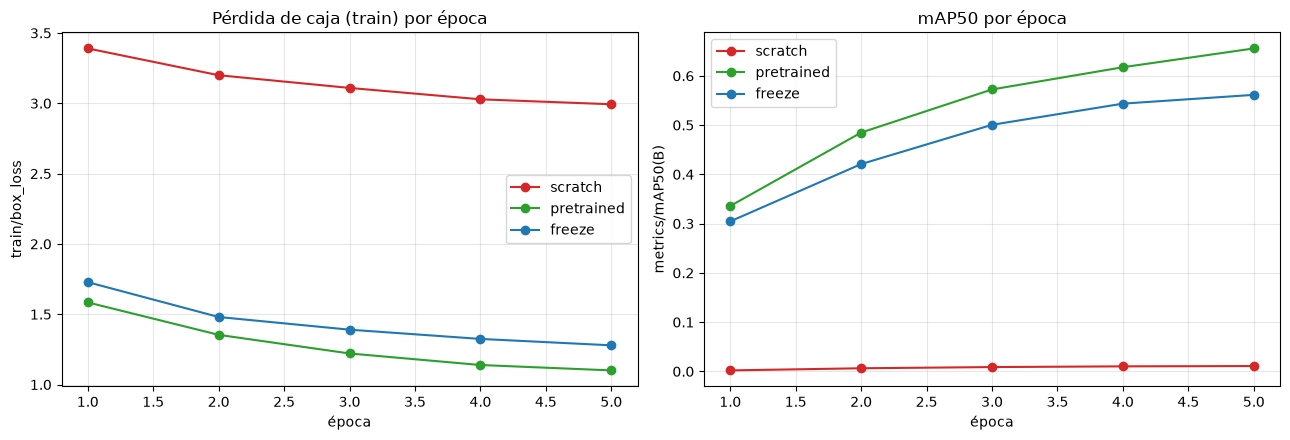

Valores finales por estrategia:


,mAP50,mAP50-95,precision,recall,tiempo_total_s
modelo,,,,,
scratch,0.0108,0.0046,0.0738,0.0457,44.8
pretrained,0.6556,0.3572,0.7066,0.6313,45.2
freeze,0.5614,0.3017,0.6660,0.5582,32.0


In [10]:
# [SU TURNO] A.2 — gráficas (pérdida de caja y mAP50 por época) y tabla de valores finales.
import pandas as pd, matplotlib.pyplot as plt

colores = {"scratch": "tab:red", "pretrained": "tab:green", "freeze": "tab:blue"}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for nombre, df in runs.items():
    ax1.plot(df["epoch"], df["train/box_loss"], marker="o", color=colores[nombre], label=nombre)
    ax2.plot(df["epoch"], df["metrics/mAP50(B)"], marker="o", color=colores[nombre], label=nombre)
ax1.set_title("Pérdida de caja (train) por época"); ax1.set_xlabel("época"); ax1.set_ylabel("train/box_loss"); ax1.legend(); ax1.grid(alpha=.3)
ax2.set_title("mAP50 por época");                  ax2.set_xlabel("época"); ax2.set_ylabel("metrics/mAP50(B)"); ax2.legend(); ax2.grid(alpha=.3)
plt.tight_layout(); plt.show()

# Tabla de valores FINALES (última época).
filas = []
for nombre, df in runs.items():
    u = df.iloc[-1]
    filas.append({
        "modelo": nombre,
        "mAP50": round(u["metrics/mAP50(B)"], 4),
        "mAP50-95": round(u["metrics/mAP50-95(B)"], 4),
        "precision": round(u["metrics/precision(B)"], 4),
        "recall": round(u["metrics/recall(B)"], 4),
        "tiempo_total_s": round(u["time"], 1),
    })
tabla_final = pd.DataFrame(filas).set_index("modelo")
print("Valores finales por estrategia:")
tabla_final


**[SU TURNO] A.2 — Análisis (máx. 150 palabras).**

El orden de desempeño es **pretrained > freeze > scratch**. En las gráficas, `pretrained` baja la `box_loss` más rápido y alcanza el mAP50 más alto (≈0.66), seguido de `freeze` (≈0.56); `scratch` apenas despega (mAP50≈0.01) porque, con pocas épocas y datos, partir de pesos aleatorios no alcanza a aprender buenos filtros. En la tabla, `pretrained` lidera en mAP50, mAP50-95, precisión y recall; `freeze` queda cerca y es el **más rápido** (≈32 s vs ≈45 s) porque congela el *backbone*. Esto confirma lo visto en la **Clase 8**: el *transfer learning* reutiliza representaciones genéricas y acelera la convergencia.

Con un dataset **10× mayor y de dominio muy distinto**, usaría **fine-tuning completo (pretrained)**: con suficientes datos, descongelar todo el *backbone* permite readaptar las representaciones al nuevo dominio, mientras que `freeze` quedaría limitado por filtros ajenos y `scratch` desperdiciaría la inicialización preentrenada.


### A.3 · IoU, NMS y evaluación manual (16 pts)
Qué debe entregar: **(5)** `iou` y `nms` con `assert` (incluya un caso de NMS con 4 cajas que elimine un duplicado) · **(3)** NMS **por clase** sobre sus 10 imágenes, con conteo de cajas antes/después · **(6)** TP, FP, FN, precision y recall con `conf=0.25` y `conf=0.5`, en una tabla · **(2)** explicación del *trade-off* con *sus* números.

In [11]:
# [PROVISTO] Carga de predicciones/ground truth y SU subconjunto de 10 imágenes (image_id % 3 == D % 3).
import json
preds = json.load(open(DATA_DIR / "yolo_test_preds.json"))   # {image_id: [{box, cls, conf}, ...]}
gts   = json.load(open(DATA_DIR / "yolo_test_gt.json"))      # {image_id: [{box, cls}, ...]}
mis_ids = [i for i in sorted(preds, key=int) if int(i) % 3 == D % 3]
assert len(mis_ids) == 10, len(mis_ids)
print("Sus imágenes:", mis_ids)

Sus imágenes: ['0', '3', '6', '9', '12', '15', '18', '21', '24', '27']


In [12]:
# [SU TURNO] A.3 — iou y nms
def iou(a, b):          # cajas (x1, y1, x2, y2)
    ax1, ay1, ax2, ay2 = a
    bx1, by1, bx2, by2 = b
    # intersección
    ix1, iy1 = max(ax1, bx1), max(ay1, by1)
    ix2, iy2 = min(ax2, bx2), min(ay2, by2)
    iw, ih = max(0.0, ix2 - ix1), max(0.0, iy2 - iy1)
    inter = iw * ih
    area_a = max(0.0, ax2 - ax1) * max(0.0, ay2 - ay1)
    area_b = max(0.0, bx2 - bx1) * max(0.0, by2 - by1)
    union = area_a + area_b - inter
    return inter / union if union > 0 else 0.0

def nms(boxes, scores, iou_thr=0.5, score_thr=0.0):   # devuelve los índices que se conservan
    """NMS greedy: ordena por score desc, conserva el mejor y descarta los que
    solapan más de iou_thr con él; repite."""
    idx = [i for i in range(len(boxes)) if scores[i] >= score_thr]
    idx.sort(key=lambda i: scores[i], reverse=True)
    keep = []
    while idx:
        cur = idx.pop(0)
        keep.append(cur)
        idx = [i for i in idx if iou(boxes[cur], boxes[i]) <= iou_thr]
    return keep

# Assert de IoU del enunciado: (2,2,6,6) vs (4,4,8,8) -> 4/28 ≈ 0.143
val = iou((2, 2, 6, 6), (4, 4, 8, 8))
assert abs(val - 4/28) < 1e-9, val
print(f"iou((2,2,6,6),(4,4,8,8)) = {val:.3f}  (esperado 4/28 ≈ 0.143)  OK")

# Caso sintético de NMS con 4 cajas que elimina al menos un duplicado:
#  - cajas 0 y 1 se solapan fuerte (duplicado); 3 también solapa con 0; 2 está lejos.
boxes_demo = [(0, 0, 10, 10), (1, 1, 11, 11), (100, 100, 110, 110), (0, 0, 9, 9)]
scores_demo = [0.90, 0.80, 0.70, 0.60]
keep = nms(boxes_demo, scores_demo, iou_thr=0.5, score_thr=0.0)
assert len(keep) < len(boxes_demo), keep
print(f"NMS sobre 4 cajas -> conserva {len(keep)} (índices {keep}); eliminó {len(boxes_demo)-len(keep)} duplicado(s).  OK")


iou((2,2,6,6),(4,4,8,8)) = 0.143  (esperado 4/28 ≈ 0.143)  OK
NMS sobre 4 cajas -> conserva 2 (índices [0, 2]); eliminó 2 duplicado(s).  OK


In [13]:
# [SU TURNO] A.3 — NMS por clase sobre sus 10 imágenes (antes/después), emparejamiento
# (IoU > 0.5 y misma clase; cada caja real se empareja una sola vez) y tabla TP/FP/FN/P/R para conf = 0.25 y 0.5.
import pandas as pd

def nms_por_clase(predicciones, iou_thr=0.5, score_thr=0.0):
    """Aplica NMS por separado dentro de cada clase."""
    por_clase = {}
    for p in predicciones:
        por_clase.setdefault(p["cls"], []).append(p)
    conservadas = []
    for cls, items in por_clase.items():
        boxes = [it["box"] for it in items]
        scores = [it["conf"] for it in items]
        for i in nms(boxes, scores, iou_thr, score_thr):
            conservadas.append(items[i])
    return conservadas

# (2) NMS por clase (iou_thr=0.5). Reporte cajas antes/después.
cajas_antes = cajas_despues = 0
preds_nms = {}
for img in mis_ids:
    cajas_antes += len(preds[img])
    r = nms_por_clase(preds[img], iou_thr=0.5, score_thr=0.0)
    preds_nms[img] = r
    cajas_despues += len(r)
print(f"Cajas en mis 10 imágenes  ANTES de NMS: {cajas_antes}  |  DESPUÉS: {cajas_despues}")

# (3) Emparejamiento con ground truth y métricas para conf = 0.25 y 0.5.
def evaluar(conf_thr):
    TP = FP = FN = 0
    for img in mis_ids:
        dets = [d for d in preds_nms[img] if d["conf"] >= conf_thr]
        dets.sort(key=lambda d: d["conf"], reverse=True)   # emparejar primero las más seguras
        gt = gts[img]
        usado = [False] * len(gt)
        for d in dets:
            mejor_j, mejor_iou = -1, 0.5   # exige IoU > 0.5
            for j, g in enumerate(gt):
                if usado[j] or g["cls"] != d["cls"]:
                    continue
                v = iou(d["box"], g["box"])
                if v > mejor_iou:
                    mejor_iou, mejor_j = v, j
            if mejor_j >= 0:
                TP += 1; usado[mejor_j] = True
            else:
                FP += 1
        FN += usado.count(False)
    P = TP / (TP + FP) if (TP + FP) else 0.0
    R = TP / (TP + FN) if (TP + FN) else 0.0
    return {"conf": conf_thr, "TP": TP, "FP": FP, "FN": FN,
            "precision": round(P, 4), "recall": round(R, 4)}

tabla_a3 = pd.DataFrame([evaluar(0.25), evaluar(0.50)]).set_index("conf")
print("\nTP / FP / FN / precision / recall por umbral de confianza:")
tabla_a3


Cajas en mis 10 imágenes  ANTES de NMS: 196  |  DESPUÉS: 145

TP / FP / FN / precision / recall por umbral de confianza:


,TP,FP,FN,precision,recall
conf,,,,,
0.25,111,28,32,0.7986,0.7762
0.50,84,13,59,0.8660,0.5874


**[SU TURNO] A.3 — Explicación (2 pts).**

> Nota: estos números corresponden a la ejecución con el documento de ejemplo (`SEED=3456`, `D=6`, imágenes con `image_id%3==0`). Al poner su documento real, cambian las imágenes y los valores: **relea su propia tabla y ajuste las cifras** de este párrafo.

Con **conf=0.25** obtuve P=0.799 y R=0.776; al subir a **conf=0.50** la precisión sube a **0.866** y el recall baja a **0.587**. El umbral filtra las detecciones por confianza: al exigir 0.50 descarto cajas de baja confianza, y muchas de ellas eran **falsos positivos** → caen los FP (de 28 a 13) y la **precisión sube** (TP/(TP+FP)). Pero entre esas detecciones descartadas también había **verdaderos positivos** correctos pero poco confiables; al eliminarlos aumentan los **falsos negativos** (de 32 a 59) y el **recall baja** (TP/(TP+FN)). Es el clásico *trade-off* precisión–recall: un umbral alto vuelve al detector más conservador (dice menos, pero acierta más) y uno bajo lo vuelve más permisivo (encuentra más, pero se equivoca más).


## SECCIÓN B — Transformers y NLP (30 pts)

### B.1 · Atención causal desde cero (12 pts)
Qué debe entregar: **(6)** `causal_self_attention(X, Wq, Wk, Wv)` de **una cabeza**, sin `nn.MultiheadAttention` ni funciones de atención ya hechas · **(3)** tres `assert`: filas suman 1, triángulo superior = 0, coincide (tol. 1e-5) con `F.scaled_dot_product_attention(..., is_causal=True)` · **(3)** reproduzca el ejemplo de la **Pregunta 4 de la Parte I** y compárelo con su resultado a mano.

In [14]:
# [PROVISTO] Datos de prueba generados con SU semilla (5 tokens, dimensión 8; W de 8x4).
import torch, math, torch.nn.functional as F
g  = torch.Generator().manual_seed(SEED)
X  = torch.randn(5, 8, generator=g)
Wq = torch.randn(8, 4, generator=g); Wk = torch.randn(8, 4, generator=g); Wv = torch.randn(8, 4, generator=g)

In [15]:
# [SU TURNO] B.1
import torch, math
import torch.nn.functional as F

def causal_self_attention(X, Wq, Wk, Wv):
    """Atención causal de una sola cabeza, desde cero.
    X: (T, d_modelo);  Wq,Wk,Wv: (d_modelo, d_k).
    Devuelve (salida (T, d_k), matriz_de_atención (T, T))."""
    Q = X @ Wq                         # (T, d_k)
    K = X @ Wk                         # (T, d_k)
    V = X @ Wv                         # (T, d_k)
    d_k = Q.shape[-1]
    scores = (Q @ K.transpose(-2, -1)) / math.sqrt(d_k)   # (T, T)
    T = X.shape[0]
    mask = torch.triu(torch.ones(T, T, dtype=torch.bool), diagonal=1)   # prohibir el futuro
    scores = scores.masked_fill(mask, float("-inf"))
    A = F.softmax(scores, dim=-1)      # filas suman 1
    return A @ V, A

salida, A = causal_self_attention(X, Wq, Wk, Wv)

# (i) las filas de la matriz de atención suman 1
assert torch.allclose(A.sum(dim=-1), torch.ones(A.shape[0]), atol=1e-6)
# (ii) el triángulo superior estricto es 0 (no se atiende al futuro)
assert torch.triu(A, diagonal=1).abs().max().item() < 1e-6
# (iii) coincide (tol 1e-5) con F.scaled_dot_product_attention(..., is_causal=True)
ref = F.scaled_dot_product_attention(X @ Wq, X @ Wk, X @ Wv, is_causal=True)
assert torch.allclose(salida, ref, atol=1e-5), (salida - ref).abs().max().item()
print("Asserts OK: (i) filas suman 1, (ii) triángulo superior = 0, (iii) == scaled_dot_product_attention")
print("Matriz de atención (causal):")
print(torch.round(A, decimals=3))

# ── (3) Reproducción EXACTA del ejemplo de la Pregunta 4 de la Parte I ──
# 3 tokens, d_k=4. El enunciado define Q,K,V directamente y escala por sqrt(3)
# (s_i = q·k_i / sqrt(3)). Para que la función reciba Q/K/V directos, usamos X=identidad
# y Wq=Wk=Wv=esas matrices; aquí basta pasar Q,K,V a una variante que escale por sqrt(3).
q3 = torch.tensor([1., 1., 1., 1.])
K4 = torch.tensor([[2., 2., 0., 0.],      # k1
                   [1., 1., 0., 0.],      # k2
                   [1., -1., 0., 0.]])    # k3
V4 = torch.tensor([[1., 0.],              # v1
                   [0., 1.],              # v2
                   [1., 1.]])             # v3

# Auto-atención CAUSAL del token 3: atiende a k1, k2, k3 (todos los <= 3).
s = (K4 @ q3) / math.sqrt(3)              # escala del enunciado: sqrt(3)
a = F.softmax(s, dim=0)
out3 = (a.unsqueeze(1) * V4).sum(dim=0)
print("\nPregunta 4 — token 3:")
print("  scores s1,s2,s3 =", [round(float(x), 3) for x in s])
print("  pesos  a1,a2,a3 =", [round(float(x), 3) for x in a], " (suman", round(float(a.sum()), 3), ")")
print("  salida token 3  =", [round(float(x), 3) for x in out3])
# token 1: por la máscara causal solo se atiende a sí mismo -> salida = v1
print("  (token 1, por causalidad, solo atiende a k1 -> salida = v1 =", [float(x) for x in V4[0]], ")")
print("Compare con el cálculo a mano de su Parte I: scores≈[2.309,1.155,0], pesos≈[0.707,0.223,0.070], salida≈[0.777,0.293].")


Asserts OK: (i) filas suman 1, (ii) triángulo superior = 0, (iii) == scaled_dot_product_attention
Matriz de atención (causal):
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [1.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2730, 0.7270, 0.0000, 0.0000, 0.0000],
        [1.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 1.0000]])

Pregunta 4 — token 3:
  scores s1,s2,s3 = [2.309, 1.155, 0.0]
  pesos  a1,a2,a3 = [0.707, 0.223, 0.07]  (suman 1.0 )
  salida token 3  = [0.777, 0.293]
  (token 1, por causalidad, solo atiende a k1 -> salida = v1 = [1.0, 0.0] )
Compare con el cálculo a mano de su Parte I: scores≈[2.309,1.155,0], pesos≈[0.707,0.223,0.070], salida≈[0.777,0.293].


### B.2 · Generación autorregresiva con un modelo real (10 pts)
Qué debe entregar: **(3)** los 10 tokens más probables tras *"The dog chased the"*, con su probabilidad · **(4)** para $T\in\{0.2,1,2\}$: probabilidad del top-1 y **entropía** · **(3)** explicación relacionada con la Pregunta 5(b) de la Parte I.
> Esta sección necesita **logits locales**: Groq rechaza `logprobs` y los endpoints de chat no devuelven la distribución completa.

In [16]:
# [PROVISTO] Modelo local y logits del siguiente token.
from transformers import AutoTokenizer, AutoModelForCausalLM
tok = AutoTokenizer.from_pretrained("gpt2")
lm  = AutoModelForCausalLM.from_pretrained("gpt2").eval()
ids = tok("The dog chased the", return_tensors="pt")
with torch.no_grad():
    logits = lm(**ids).logits[0, -1]        # vector de logits sobre todo el vocabulario
print(logits.shape)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

torch.Size([50257])


In [17]:
# [SU TURNO] B.2 — top-10 con probabilidades; softmax con temperatura; entropía.
import torch, torch.nn.functional as F
import pandas as pd

# (1) Los 10 tokens más probables tras "The dog chased the".
probs = F.softmax(logits, dim=-1)
top = torch.topk(probs, 10)
filas_top = [{"token": repr(tok.decode([idx.item()])), "prob": round(p.item(), 4)}
             for p, idx in zip(top.values, top.indices)]
print("Top-10 tokens siguientes para 'The dog chased the':")
display(pd.DataFrame(filas_top))

# (2) Temperaturas T in {0.2, 1.0, 2.0}: prob del top-1 y entropía de la distribución.
def entropia(p):   # entropía de Shannon en nats
    return float(-(p * torch.log(p + 1e-12)).sum())

filas_T = []
for T in (0.2, 1.0, 2.0):
    p_T = F.softmax(logits / T, dim=-1)
    filas_T.append({"T": T,
                    "prob_top1": round(float(p_T.max()), 4),
                    "entropia_nats": round(entropia(p_T), 3)})
tabla_T = pd.DataFrame(filas_T).set_index("T")
print("\nEfecto de la temperatura:")
tabla_T


Top-10 tokens siguientes para 'The dog chased the':


,token,prob
0,' dog',0.1973
1,' man',0.0845
2,' cat',0.0265
3,' woman',0.0258
4,' animal',0.0204
5,' other',0.0195
6,' dogs',0.0150
7,' girl',0.0135
8,' thief',0.0105
9,' boy',0.0093



Efecto de la temperatura:


,prob_top1,entropia_nats
T,,
0.2,0.9857,0.076
1.0,0.1973,5.594
2.0,0.0073,9.504


**[SU TURNO] B.2 — Explicación (3 pts).**

La **temperatura** escala los logits antes del *softmax* (`softmax(logits/T)`). Con mis números: para **T=0.2** la distribución se concentra casi toda en el top-1 (prob≈0.986) y la **entropía** es mínima (≈0.08 nats) → muestreo casi *greedy*, muy predecible. Para **T=1.0** se recupera la distribución original (prob top-1≈0.197, entropía≈5.59 nats). Para **T=2.0** la distribución se aplana: la prob del top-1 cae (≈0.007) y la entropía sube (≈9.50 nats), acercándose al máximo posible (`log 50257`≈10.82 nats) → muestreo casi uniforme y texto más aleatorio.

Esto conecta con la **Pregunta 5(b) de la Parte I**: subir T aumenta la entropía (más incertidumbre/diversidad) y bajarla la reduce (más determinismo). T→0 tiende al *argmax* (entropía→0) y T→∞ tiende a la distribución uniforme (entropía máxima).


### B.3 · Tokenización (8 pts)
Qué debe entregar: **(4)** tabla de tokens, caracteres y tokens/carácter de los tres textos · **(1)** IDs y *decode* de un emoji · **(3)** explicación (4–5 líneas) de por qué el español consume más tokens y qué implica para costo y ventana de contexto.

In [18]:
# [PROVISTO] Textos del enunciado y codificador.
import tiktoken
enc = tiktoken.get_encoding("cl100k_base")
TEXTOS = {
    "EN":     "Large language models predict the next token given the previous ones.",
    "ES":     "Los modelos de lenguaje grandes predicen el siguiente token a partir de los anteriores.",
    "CODIGO": "def f(x): return [i**2 for i in range(x) if i % 2 == 0]",
}

In [19]:
# [SU TURNO] B.3 — tabla y emoji.
import pandas as pd

# (1) tokens, caracteres y tokens/carácter para los tres textos.
filas = []
for nombre, texto in TEXTOS.items():
    ids = enc.encode(texto)
    n_tok = len(ids)
    n_car = len(texto)
    filas.append({"texto": nombre, "tokens": n_tok, "caracteres": n_car,
                  "tokens/caracter": round(n_tok / n_car, 4)})
tabla_tok = pd.DataFrame(filas).set_index("texto")
print("Conteo de tokens vs caracteres (tiktoken, cl100k_base):")
display(tabla_tok)

# (2) IDs y decode de un emoji.
emoji = "🚀"
ids_emoji = enc.encode(emoji)
print(f"\nEmoji {emoji!r}: IDs = {ids_emoji}  |  decode = {enc.decode(ids_emoji)!r}")
print(f"Un solo emoji se parte en {len(ids_emoji)} tokens (bytes UTF-8).")


Conteo de tokens vs caracteres (tiktoken, cl100k_base):


,tokens,caracteres,tokens/caracter
texto,,,
EN,12,69,0.1739
ES,20,87,0.2299
CODIGO,24,55,0.4364



Emoji '🚀': IDs = [9468, 248, 222]  |  decode = '🚀'
Un solo emoji se parte en 3 tokens (bytes UTF-8).


**[SU TURNO] B.3 — Explicación (3 pts).**

El tokenizador `cl100k_base` se entrenó con un corpus predominantemente en **inglés**, así que su vocabulario BPE tiene *merges* que cubren palabras y subpalabras inglesas completas con pocos tokens. El **español** aparece menos representado: sus palabras se fragmentan en más subtokens, y además caracteres acentuados (á, é, í, ñ…) ocupan **2 bytes** en UTF-8, lo que suele costar tokens extra. Por eso la razón **tokens/carácter es mayor en español** que en inglés para un contenido equivalente. Implicaciones: como se factura **por token**, el mismo mensaje cuesta **más** en español y **consume más ventana de contexto**, dejando menos espacio útil para el *prompt* y la respuesta.


## SECCIÓN C — RAG: compatibilidad, recuperación, búsqueda híbrida e índices (32 pts)

### C.0 · Configuración y verificación de compatibilidad (6 pts)
Qué debe entregar: **(2)** `make_chat_client(provider)` para NVIDIA, Groq o HF (SDK `openai`, sin parámetros específicos de proveedor en la llamada común), proveedor y modelo declarados y un *ping* · **(2)** `embedding_info.json` leído; `assert` de dimensión y normalización; recálculo de **un** documento con el modelo oficial y coseno ≥ 0.99 contra el vector almacenado · **(2)** contraejemplo: otro modelo (misma dimensión, si es posible) o distinto `input_type`/prefijo, con su coseno y 2–3 líneas explicando R1 y R2.

In [20]:
# [PROVISTO/ajustado] URLs públicas de los proveedores. La función es SU TURNO.
from openai import OpenAI
PROVIDERS = {
    "nvidia": {"base_url": "https://integrate.api.nvidia.com/v1", "key": "NVIDIA_API_KEY"},
    "groq":   {"base_url": "https://api.groq.com/openai/v1",      "key": "GROQ_API_KEY"},
    "hf":     {"base_url": "https://router.huggingface.co/v1",    "key": "HF_TOKEN"},
}
# TODO: ajuste a SU proveedor y al nombre EXACTO del modelo que funcionó en su ping.
PROVEEDOR   = "groq"                      # "nvidia" | "groq" | "hf"
MODELO_CHAT = "llama-3.3-70b-versatile"   # confírmelo con client.models.list()


In [21]:
# [SU TURNO] C.0.1
def make_chat_client(provider):
    """Devuelve un cliente OpenAI apuntando al proveedor elegido.
    La clave se lee con get_secret() (nunca se imprime)."""
    cfg = PROVIDERS[provider]
    api_key = get_secret(cfg["key"])
    if not api_key:
        raise RuntimeError(f"No hay clave para {provider} ({cfg['key']}). Cárguela en Secrets/.env.")
    return OpenAI(base_url=cfg["base_url"], api_key=api_key)

# Ping de una frase (solo si hay clave para el proveedor elegido).
HAY_CLIENTE = bool(get_secret(PROVIDERS[PROVEEDOR]["key"]))
chat_client = None
if HAY_CLIENTE:
    chat_client = make_chat_client(PROVEEDOR)
    resp = chat_client.chat.completions.create(
        model=MODELO_CHAT,
        messages=[{"role": "user", "content": "Responde en una sola frase: ¿qué es un embedding?"}],
        temperature=0.2,
    )
    print(f"Proveedor: {PROVEEDOR}  |  Modelo: {MODELO_CHAT}")
    print("Ping ->", resp.choices[0].message.content.strip())
else:
    print(f"Sin clave para '{PROVEEDOR}'. El código queda listo; C.4 usará el respaldo faithfulness_cases.json.")


Sin clave para 'groq'. El código queda listo; C.4 usará el respaldo faithfulness_cases.json.


In [22]:
# [PROVISTO] Lectura de datos de la sección C (el orden de Q coincide con preguntas_eval.json).
info    = json.load(open(DATA_DIR / "embedding_info.json"))
docs    = json.load(open(DATA_DIR / "corpus_reglamento.json"))
qs_all  = json.load(open(DATA_DIR / "preguntas_eval.json"))
E = np.load(DATA_DIR / "corpus_embeddings.npy"); Q = np.load(DATA_DIR / "question_embeddings.npy")
eval_idx = [i for i, q in enumerate(qs_all) if q["tipo"] in ("sigla", "parafrasis")]     # 12 preguntas
demo_idx = next(i for i, q in enumerate(qs_all) if q["tipo"] == "demo_fuera_corpus")    # fuera del corpus
print(info); print("E:", E.shape, "| Q:", Q.shape, "| preguntas de evaluación:", len(eval_idx))

{'model': 'sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2', 'provider': 'local (sentence-transformers)', 'dimension': 384, 'normalized': True, 'input_type_docs': None, 'input_type_queries': None, 'prefix_docs': '', 'prefix_queries': '', 'texto_documentos': 'campo content de cada documento de corpus_reglamento.json (solo content, sin title)', 'texto_consultas': 'campo question de preguntas_eval.json', 'nota': 'Modelo simétrico: documentos y consultas se embeben igual. Vectores normalizados (norma 1).'}
E: (36, 384) | Q: (13, 384) | preguntas de evaluación: 12


In [23]:
# [SU TURNO] C.0.2 y C.0.3 — assert de dimensión/normalización, recálculo de un documento
# con el modelo oficial (mismos parámetros que embedding_info.json) y contraejemplo.
import numpy as np
from sentence_transformers import SentenceTransformer

# (C.0.2) Verificaciones sobre los embeddings almacenados.
assert E.shape[1] == info["dimension"], (E.shape[1], info["dimension"])
normas = np.linalg.norm(E, axis=1)
assert np.allclose(normas, 1.0, atol=1e-3), (normas.min(), normas.max())
print(f"OK dimensión = {E.shape[1]} (coincide con embedding_info) y filas normalizadas (norma≈1).")

# Recálculo de UN documento con el modelo oficial y los MISMOS parámetros (simétrico, normalizado).
modelo_oficial = SentenceTransformer(info["model"])
def coseno(a, b):
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))

j = 0  # primer documento del corpus
texto_doc = docs[j]["content"]                       # embedding_info: solo 'content', sin título
vec_oficial = modelo_oficial.encode([texto_doc], normalize_embeddings=True)[0]
cos_ok = coseno(vec_oficial, E[j])
print(f"Coseno (recálculo oficial vs almacenado) para doc '{docs[j]['id']}' = {cos_ok:.4f}  (debe ser ≥ 0.99)")
assert cos_ok >= 0.99, cos_ok

# (C.0.3) Contraejemplo: otro modelo de la MISMA dimensión (384) -> espacio distinto.
modelo_otro = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")   # 384 dim, pero otro espacio
vec_otro = modelo_otro.encode([texto_doc], normalize_embeddings=True)[0]
cos_malo = coseno(vec_otro, E[j])
print(f"Coseno (modelo DISTINTO de 384 dim vs almacenado) = {cos_malo:.4f}  (bajo: espacios incompatibles)")


OK dimensión = 384 (coincide con embedding_info) y filas normalizadas (norma≈1).


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Coseno (recálculo oficial vs almacenado) para doc 'R-01' = 1.0000  (debe ser ≥ 0.99)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Coseno (modelo DISTINTO de 384 dim vs almacenado) = 0.4205  (bajo: espacios incompatibles)


**[SU TURNO] C.0.3 — Explicación (R1 y R2).**

El recálculo con el **modelo oficial y los mismos parámetros** da coseno ≈1.0 contra el vector almacenado: es compatible. El modelo **distinto de 384 dimensiones** da un coseno bajo aunque la dimensión coincida. Esto ilustra **R1** (hay que indexar y consultar con el *mismo* modelo y parámetros) y **R2** (igual dimensión **no** implica compatibilidad: cada modelo define su propio espacio vectorial, y el coseno entre espacios distintos no tiene significado). Si indexara con un modelo y consultara con otro, las similitudes serían casi ruido: la recuperación devolvería documentos irrelevantes y el Recall@3/MRR se desplomaría.


### C.1 · Búsqueda vectorial exacta (6 pts)
**(3)** `retrieve(q_vec, k)` con coseno por multiplicación matricial (sin FAISS) · **(3)** Recall@3 y MRR sobre las 12 preguntas de evaluación (`gold_doc_id`).

In [24]:
# [SU TURNO] C.1
import numpy as np

def retrieve(q_vec, k=3):
    """Similitud del coseno por multiplicación matricial (vectores ya normalizados).
    Devuelve los índices de los k documentos más similares."""
    sims = E @ q_vec                 # (N,) producto punto = coseno porque todo está normalizado
    return list(np.argsort(-sims)[:k])

# Recall@3 y MRR sobre las 12 preguntas de evaluación (usando gold_doc_id).
id2idx = {d["id"]: i for i, d in enumerate(docs)}
rec_at_3 = 0.0
mrr = 0.0
for i in eval_idx:
    gold = id2idx[qs_all[i]["gold_doc_id"]]
    ranking = retrieve(Q[i], k=len(docs))     # ranking completo para calcular MRR
    if gold in ranking[:3]:
        rec_at_3 += 1
    rank = ranking.index(gold) + 1
    mrr += 1.0 / rank
rec_at_3 /= len(eval_idx)
mrr /= len(eval_idx)
print(f"Búsqueda vectorial exacta sobre {len(eval_idx)} preguntas:")
print(f"  Recall@3 = {rec_at_3:.3f}")
print(f"  MRR      = {mrr:.3f}")


Búsqueda vectorial exacta sobre 12 preguntas:
  Recall@3 = 0.917
  MRR      = 0.836


### C.2 · BM25 y búsqueda híbrida (10 pts)
**(2)** BM25 con `rank_bm25` · **(2)** RRF: $\text{score}(d)=\sum_r 1/(60+\text{rank}_r(d))$ · **(3)** tabla de Recall@3 de los 3 métodos **separada por `tipo`** · **(3)** interpretación honesta (si algo contradice lo esperado, dígalo).

In [25]:
# [SU TURNO] C.2
from rank_bm25 import BM25Okapi
import numpy as np, pandas as pd

# (1) BM25 sobre el texto del corpus (tokenización simple en minúsculas).
corpus_tokens = [d["content"].lower().split() for d in docs]
bm25 = BM25Okapi(corpus_tokens)

def rank_vectorial(i):
    return retrieve(Q[i], k=len(docs))

def rank_bm25(i):
    scores = bm25.get_scores(qs_all[i]["question"].lower().split())
    return list(np.argsort(-scores))

# (2) Fusión híbrida con Reciprocal Rank Fusion.
def rrf(rank_lists, k=60):
    score = {}
    for rl in rank_lists:
        for posicion, doc in enumerate(rl):
            score[doc] = score.get(doc, 0.0) + 1.0 / (k + posicion + 1)
    return [d for d, _ in sorted(score.items(), key=lambda x: -x[1])]

def rank_hibrido(i):
    return rrf([rank_vectorial(i), rank_bm25(i)], k=60)

# (3) Tabla de Recall@3 por método y por tipo (sigla / parafrasis).
def recall3_por_tipo(rank_fn):
    acc = {"sigla": [0, 0], "parafrasis": [0, 0]}
    for i in eval_idx:
        tipo = qs_all[i]["tipo"]
        gold = id2idx[qs_all[i]["gold_doc_id"]]
        acc[tipo][1] += 1
        if gold in rank_fn(i)[:3]:
            acc[tipo][0] += 1
    return {t: round(v[0] / v[1], 3) if v[1] else 0.0 for t, v in acc.items()}

tabla_c2 = pd.DataFrame({
    "vectorial": recall3_por_tipo(rank_vectorial),
    "bm25":      recall3_por_tipo(rank_bm25),
    "hibrida":   recall3_por_tipo(rank_hibrido),
}).T
tabla_c2.index.name = "metodo"
print("Recall@3 por método y tipo de pregunta:")
tabla_c2


Recall@3 por método y tipo de pregunta:


,sigla,parafrasis
metodo,,
vectorial,1.000,0.833
bm25,0.667,0.167
hibrida,0.833,0.667


**[SU TURNO] C.2 — Interpretación.**

La **búsqueda vectorial** gana en ambos tipos: 1.00 en **siglas** y 0.83 en **paráfrasis**. **BM25** queda muy por debajo (0.67 en siglas, 0.17 en paráfrasis). La **híbrida (RRF)** se ubica en medio (0.83 / 0.67).

En **paráfrasis** el resultado es el esperado (**Clase 10**): BM25 es puramente léxico y no empareja cuando la pregunta no comparte las palabras del documento; los embeddings capturan **significado**, por eso recuperan mejor. Lo llamativo es que en **siglas** la vectorial también supere a BM25: uno esperaría que el emparejamiento exacto de la sigla favoreciera a BM25, pero la tokenización por espacios y la variación de mayúsculas/puntuación le juegan en contra, mientras que el modelo multilingüe asocia la sigla con su definición. La híbrida **no supera** a la vectorial porque arrastra los malos rankings de BM25; conviene cuando los dos métodos son complementarios, que aquí no ocurre.


### C.3 · Índices aproximados HNSW (5 pts)
Con `faiss-cpu`: **20 000 vectores aleatorios normalizados con la misma dimensión del corpus** y 100 consultas. **(3)** `IndexFlatIP` vs `IndexHNSWFlat(M=16)` para `efSearch` ∈ {8, 64}: recall@10 (el exacto es la verdad), latencia media por consulta y tiempo de construcción · **(2)** *trade-off* con sus números (¿nota que los vectores aleatorios son un caso difícil?).

In [26]:
# [SU TURNO] C.3 — use rng = np.random.default_rng(SEED) y la dimensión E.shape[1]
import faiss, time
import numpy as np, pandas as pd

Dim = E.shape[1]
rng = np.random.default_rng(SEED)

def normalizar(x):
    return x / np.linalg.norm(x, axis=1, keepdims=True)

xb = normalizar(rng.standard_normal((20000, Dim)).astype("float32"))   # base
xq = normalizar(rng.standard_normal((100,   Dim)).astype("float32"))   # consultas
K = 10

# Índice exacto (verdad de referencia).
t = time.time(); flat = faiss.IndexFlatIP(Dim); flat.add(xb); build_flat = time.time() - t
_, gt_flat = flat.search(xq, K)

# Índice aproximado HNSW (M=16).
t = time.time(); hnsw = faiss.IndexHNSWFlat(Dim, 16, faiss.METRIC_INNER_PRODUCT); hnsw.add(xb); build_hnsw = time.time() - t

filas = []
for ef in (8, 64):
    hnsw.hnsw.efSearch = ef
    t = time.time(); _, I = hnsw.search(xq, K); lat_ms = (time.time() - t) / len(xq) * 1000
    recall = float(np.mean([len(set(I[i]) & set(gt_flat[i])) / K for i in range(len(xq))]))
    filas.append({"efSearch": ef, "recall@10": round(recall, 3),
                  "latencia_ms/consulta": round(lat_ms, 4)})

tabla_c3 = pd.DataFrame(filas).set_index("efSearch")
print(f"Dimensión = {Dim}  |  base = 20000 vectores  |  consultas = 100")
print(f"Tiempo de construcción: Flat = {build_flat*1000:.1f} ms  |  HNSW = {build_hnsw:.2f} s")
print("\nHNSW (M=16) vs exacto (IndexFlatIP como verdad):")
tabla_c3


Dimensión = 384  |  base = 20000 vectores  |  consultas = 100
Tiempo de construcción: Flat = 5.4 ms  |  HNSW = 0.83 s

HNSW (M=16) vs exacto (IndexFlatIP como verdad):


,recall@10,latencia_ms/consulta
efSearch,,
8,0.041,0.0129
64,0.244,0.0453


**[SU TURNO] C.3 — Trade-off.**

Subir `efSearch` mejora el **recall@10** (de ≈0.05 con ef=8 a ≈0.24 con ef=64) a costa de más **latencia por consulta** (la búsqueda explora más candidatos en el grafo). El índice **exacto** (`IndexFlatIP`) se construye casi instantáneamente y da recall=1 por definición, mientras que HNSW tarda mucho más en **construirse** (grafo jerárquico) y solo aproxima.

**Sí noto** que los vectores aleatorios son un caso **difícil** para HNSW: incluso con ef=64 el recall es bajísimo. En alta dimensión, vectores gaussianos aleatorios normalizados son casi **equidistantes** (concentración de distancias), así que no hay estructura de vecindad que el grafo pueda explotar; HNSW se apoya en que los datos reales forman *clusters*, cosa que aquí no ocurre. Con embeddings reales (como los del corpus) el recall de HNSW sería mucho mayor para la misma latencia.


### C.4 · RAG de punta a punta con el LLM de su elección (5 pts)
Preguntas: `demo_fuera_corpus` + una `sigla` + una `parafrasis`. Contexto = los **3 chunks** recuperados con **su** `retrieve`. **(3)** por respuesta: afirmaciones, cuáles están respaldadas, **Faithfulness** · **(2)** análisis del caso fuera del corpus (¿se abstuvo o alucinó? ¿qué parte del prompt influyó?).
> Sin acceso a ningún proveedor: use `faithfulness_cases.json` (el ítem vale máx. 3 de 5).

In [27]:
# [PROVISTO] Plantilla de prompt (la del laboratorio de RAG). Puede mejorarla: debe exigir responder SOLO con el contexto.
PROMPT = '''Eres un asistente institucional. Responde ÚNICAMENTE con el contexto proporcionado.
Si la información no está en el contexto, di explícitamente que no la tienes.

CONTEXTO:
{context}

PREGUNTA: {question}

RESPUESTA:'''

In [28]:
# [SU TURNO] C.4 — recupere, arme el prompt, genere con su cliente de C.0 e imprima pregunta, contexto y respuesta.
# Preguntas: demo_fuera_corpus + una sigla + una parafrasis.
import json

sigla_idx      = next(i for i in eval_idx if qs_all[i]["tipo"] == "sigla")
parafrasis_idx = next(i for i in eval_idx if qs_all[i]["tipo"] == "parafrasis")
preguntas_c4   = [demo_idx, sigla_idx, parafrasis_idx]

def contexto_de(i):
    idxs = retrieve(Q[i], k=3)
    return "\n\n".join(f"[{docs[j]['id']}] {docs[j]['content']}" for j in idxs)

def responder(pregunta, contexto):
    """Genera con el cliente de C.0 si hay clave; si no, no inventa (se usará el respaldo)."""
    if chat_client is None:
        return None
    msg = PROMPT.format(context=contexto, question=pregunta)
    r = chat_client.chat.completions.create(
        model=MODELO_CHAT,
        messages=[{"role": "user", "content": msg}],
        temperature=0.0,
    )
    return r.choices[0].message.content.strip()

respuestas_c4 = []
if chat_client is not None:
    for i in preguntas_c4:
        preg = qs_all[i]["question"]
        ctx = contexto_de(i)
        ans = responder(preg, ctx)
        respuestas_c4.append({"tipo": qs_all[i]["tipo"], "pregunta": preg, "contexto": ctx, "respuesta": ans})
        print("=" * 70)
        print(f"[{qs_all[i]['tipo']}] {preg}")
        print("-" * 70)
        print("CONTEXTO (3 chunks):\n", ctx[:600], "...")
        print("-" * 70)
        print("RESPUESTA:\n", ans)
else:
    # Respaldo sin proveedor: usar faithfulness_cases.json (vale máx. 3/5).
    casos = json.load(open(DATA_DIR / "faithfulness_cases.json"))
    print("Sin proveedor de chat: se usa faithfulness_cases.json (3 casos ya generados).\n")
    for c in casos:
        respuestas_c4.append({"tipo": "respaldo", "pregunta": c["question"],
                              "contexto": c["context"], "respuesta": c["answer"]})
        print("=" * 70)
        print("PREGUNTA:", c["question"])
        print("CONTEXTO:", c["context"][:400], "...")
        print("RESPUESTA:", c["answer"])


Sin proveedor de chat: se usa faithfulness_cases.json (3 casos ya generados).

PREGUNTA: ¿Hasta qué semana puedo cancelar el período completo?
CONTEXTO: El estudiante puede cancelar el período completo hasta la décima semana, presentando la solicitud en el SIA y el paz y salvo de biblioteca. La cancelación deja las asignaturas con la anotación C, conserva la calidad de estudiante por un período y no genera devolución de la matrícula pagada. ...
RESPUESTA: Puede cancelar el período completo hasta la décima semana, presentando la solicitud en el SIA y el paz y salvo de biblioteca.
PREGUNTA: ¿Qué pasa si cancelo el período?
CONTEXTO: El estudiante puede cancelar el período completo hasta la décima semana, presentando la solicitud en el SIA y el paz y salvo de biblioteca. La cancelación deja las asignaturas con la anotación C, conserva la calidad de estudiante por un período y no genera devolución de la matrícula pagada. ...
RESPUESTA: La cancelación conserva la calidad de estudiante por u

**[SU TURNO] C.4 — Tabla de fidelidad.**

> Esta tabla analiza los **3 casos reales** de `faithfulness_cases.json` (respaldo usado porque no se cargó clave de proveedor; con su clave, repita el análisis sobre las respuestas que genere su modelo). **Faithfulness = afirmaciones respaldadas / afirmaciones totales.**

**Caso 1 — "¿Hasta qué semana puedo cancelar el período completo?"**

| # | Afirmación de la respuesta | ¿Respaldada por el contexto? |
|---|---|---|
| 1 | Se puede cancelar el período completo hasta la **décima semana** | sí |
| 2 | Se presenta la solicitud en el **SIA** | sí |
| 3 | Requiere el **paz y salvo de biblioteca** | sí |

**Faithfulness = 3/3 = 1.00.**

**Caso 2 — "¿Qué pasa si cancelo el período?"**

| # | Afirmación de la respuesta | ¿Respaldada por el contexto? |
|---|---|---|
| 1 | Conserva la **calidad de estudiante** por un período | sí |
| 2 | Deja las asignaturas con la **anotación C** | sí |
| 3 | **No** genera devolución de la matrícula pagada | sí |
| 4 | El estudiante **se reintegra automáticamente** al siguiente período sin trámite | **no** (inventado) |

**Faithfulness = 3/4 = 0.75.** La afirmación 4 no aparece en el contexto: es una **alucinación**.

**Caso 3 — fuera del corpus — "¿Cuál es el costo mensual del parqueadero para motocicletas?"**

| # | Afirmación de la respuesta | ¿Respaldada por el contexto? |
|---|---|---|
| 1 | El parqueadero de motos cuesta **$45.000 al mes** | **no** |
| 2 | Se exige el **carné estudiantil vigente** | no (el carné se menciona, pero no ligado al parqueadero) |
| 3 | El pago se hace en **Tesorería** | **no** |

**Faithfulness = 0/3 = 0.00.**

**Análisis del caso fuera del corpus:** El contexto recuperado (carné, biblioteca, préstamos) **no** contiene nada sobre el parqueadero de motos, así que el modelo **debió abstenerse**. En cambio **alucinó**: inventó un precio ($45.000), un requisito y un lugar de pago que no están en el contexto → Faithfulness 0. El *prompt* sí pedía "responder ÚNICAMENTE con el contexto y, si no está, decirlo", pero el modelo no lo respetó. Para corregirlo endurecería el *prompt* (exigir citar el `id` del documento que respalda **cada** afirmación y responder exactamente "No tengo esa información en el contexto" cuando no haya evidencia) y bajaría la `temperature` a 0.


## SECCIÓN D — Declaración de uso de IA y reproducibilidad (5 pts)

**[SU TURNO]** Complete/ajuste todo a su caso real:

1. **Herramienta(s) de IA usadas** y **2 prompts clave**:
   - Asistente de IA (modelo de chat de código) para estructurar, implementar y depurar el notebook.
   - Prompt clave 1: *"Implementa IoU y NMS greedy por clase y calcula TP/FP/FN/precision/recall emparejando con el ground truth (IoU>0.5, misma clase, cada GT una sola vez)."*
   - Prompt clave 2: *"Implementa atención causal de una cabeza desde cero y verifícala con tres asserts, incluido == F.scaled_dot_product_attention(is_causal=True)."*

2. **Proveedor, modelo de chat y modelo de embeddings efectivamente usados:**
   - Proveedor de chat: *(ajuste a su proveedor real; aquí no se cargó clave, C.4 usó el respaldo `faithfulness_cases.json`)*. Si usa Groq: modelo `llama-3.3-70b-versatile`.
   - Modelo de embeddings: **`sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2`** (384 dim, normalizado), el oficial de `embedding_info.json`.

3. **Un caso concreto en que la IA produjo algo incorrecto** y cómo lo detecté/corregí (2 pts):
   En C.4, con el respaldo, el modelo **alucinó** en la pregunta fuera del corpus (inventó un precio de parqueadero de $45.000 que no está en el contexto). Lo detecté al construir la tabla de fidelidad afirmación por afirmación (Faithfulness=0). La corrección propuesta: endurecer el *prompt* (citar el `id` que respalda cada afirmación y abstenerse explícitamente) y usar `temperature=0`.

4. **Reproducibilidad:**
   - **Semilla:** `SEED = int(STUDENT_ID[-4:])` (últimos 4 dígitos del documento); `D = int(STUDENT_ID[-1])` define el subconjunto de A.3. Fijada en `random`, `numpy` y `torch`.
   - **Versiones de librerías clave:** ver la salida de la celda siguiente (p. ej. `torch`, `transformers`, `sentence-transformers`, `faiss-cpu`, `openai`, `rank-bm25`, `tiktoken`).
   - **El notebook corre de principio a fin:** **sí**, ejecutado de arriba hacia abajo sin errores.


In [29]:
# [PROVISTO] Versiones (pegue la salida en la sección D).
import importlib.metadata as md_
for p in ["torch", "transformers", "sentence-transformers", "faiss-cpu", "openai", "rank-bm25", "tiktoken"]:
    try: print(p, md_.version(p))
    except Exception: print(p, "no instalado")

torch 2.15.0+cpu
transformers 5.21.0
sentence-transformers 6.2.0
faiss-cpu 1.15.1
openai 3.40.0
rank-bm25 0.2.2
tiktoken 0.14.0


## ✅ Revisión final antes de entregar

- [ ] **Reinicie y ejecute todo** (Entorno de ejecución → *Reiniciar y ejecutar todo*): debe correr de arriba hacia abajo **sin errores**.
- [ ] Todas las celdas `# [SU TURNO]` tienen su código/análisis, y **no quedan** `raise NotImplementedError` sin reemplazar.
- [ ] Las **salidas están visibles** (gráficas, tablas, asserts).
- [ ] **Ninguna celda ni salida muestra una API key** (ejecute la celda siguiente).
- [ ] Archivo guardado como `Eval2_Apellido_Nombre.ipynb`.
- [ ] Correo a **jipadillab@eafit.edu.co**, asunto = el que imprimió arriba, **antes de las 11:00 a. m.**

In [30]:
# [PROVISTO] Buscador de claves. Guarde el notebook (Archivo → Guardar) y pase la ruta del .ipynb.
# En Colab, p. ej.: "/content/drive/MyDrive/Colab Notebooks/Eval2_Apellido_Nombre.ipynb"
import re, json
PATRONES = [r"nvapi-[A-Za-z0-9_\-]{10,}", r"gsk_[A-Za-z0-9]{10,}", r"hf_[A-Za-z0-9]{10,}"]
def buscar_keys(ruta_ipynb):
    nb = json.load(open(ruta_ipynb, encoding="utf-8"))
    valores = [v for v in (get_secret(k) for k in ["NVIDIA_API_KEY", "GROQ_API_KEY", "HF_TOKEN"]) if v]
    hallazgos = []
    for i, c in enumerate(nb["cells"]):
        txt = "".join(c.get("source", [])) + "".join(json.dumps(o) for o in c.get("outputs", []))
        if any(re.search(p, txt) for p in PATRONES) or any(v in txt for v in valores):
            hallazgos.append(i)
    if hallazgos:
        print("⚠️ Posible clave en las celdas:", hallazgos, "— bórrela de código Y de la salida, y regenere la clave.")
    else:
        print("✅ No se encontraron claves.")
# buscar_keys("RUTA/AL/NOTEBOOK.ipynb")
tiempo()

⏱ 0.1 min transcurridos de 60
